# Stitching explained: what the method does, in pictures

We take the **encoder** of one Diffusion Policy agent and the **controller** of another, trained separately in
different domains, and connect them through a linear map fitted **without paired frames**: only from the robot's
motion in each agent's own demos. This notebook shows each step on real checkpoints and demos. It trains nothing;
its only closed-loop footage comes from `scripts/notebook_rollouts.py` (10 illustrative episodes per map).

Figures are also saved to `results/20261015_notebook/`. Run from the repo root or from `notebooks/`.
The GPU is used for encoding only if no other process holds it; otherwise everything runs on CPU.

In [1]:
import json, os, subprocess, sys
from pathlib import Path

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path[:0] = [str(ROOT), str(ROOT / "scripts"), str(ROOT / "third_party/maniskill_diffusion_policy")]
os.chdir(ROOT)

# check the GPU before anything touches CUDA: a running training job owns it
busy = subprocess.run(["nvidia-smi", "--query-compute-apps=pid", "--format=csv,noheader"], capture_output=True, text=True).stdout.strip()

import h5py
import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import HTML, Image, Video, display

import step1b_stitch as s1
import step5b_stitch as s5
from stitch.align import fit_affine_paired, fit_identity, fit_procrustes_paired

DEV = "cuda" if torch.cuda.is_available() and not busy else "cpu"
s1.DEV = s5.DEV = DEV  # load_agent, encode and nearest read these module globals
print("device:", DEV)

/home/ricc/projects/labelstitch-nb/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda


In [2]:
P = "/home/ricc/projects"
TRAJ = "trajectory.rgb.pd_ee_delta_pos.physx_cpu.h5"
s5.H5.update({  # DP-format demos; the same demo index and step is the same state in every rendering of a (task, robot)
    "cam0": f"{P}/labelstitch-step1/results/20260930_dp_ours_demos_default_panda_cam0_lollipop/{TRAJ}",
    "look2": f"{P}/labelstitch-1b/results/20261002_dp_ours_demos_default_panda_cam0_look2_lollipop/{TRAJ}",
    "look2_r": f"{P}/labelstitch-r/results/20261002_dp_ours_demos_default_panda_cam0_look2_lollipop/{TRAJ}",  # copy used by the embodiment runs
    "xarm_look2": f"{P}/labelstitch-r/results/20261003_dp_ours_demos_default_xarm6_cam0_look2_lollipop/{TRAJ}",
    "xarm_cam0": f"{P}/labelstitch-r/results/20261003_dp_ours_demos_default_xarm6_cam0_lollipop/{TRAJ}"})
RUNS = {"cam0_s1": f"{P}/labelstitch-step1/results/20261001_step2g_dp_core_nograsp_50k_s1",
        "look2_s2": f"{P}/labelstitch-1b/results/20261002_step1b_dp_ref_look2_s2",
        "look2_s1": f"{P}/labelstitch-1b/results/20261003_step1b_dp_ref_look2_s1",
        "xarm_cam0_s2": f"{P}/labelstitch-1b/results/20261004_step1b_dp_ref_xarm_cam0_100k_s2"}
# existing closed-loop numbers (250 episodes for the visual pair, 1000 for the embodiment pair); quoted, not recomputed
MATRIX_1B = f"{P}/labelstitch-1b/results/20261003_step1b_matrix/metrics.json"
MOTION_P1 = f"{P}/labelstitch-5b/results/20261013_step5b_motion_matrix_look2_p1/metrics.json"
ORTH_P1 = f"{P}/labelstitch-5b/results/20261014_step5b_motion_matrix_look2_p1_sim/metrics.json"
EMB_CEIL = f"{P}/labelstitch-5b/results/20261014_step5b_motion_stepR_emb_p1_ceil1000/metrics.json"
EMB_OWN = f"{P}/labelstitch-5b/results/20261013_step5b_motion_stepR_emb_p1_own1000/metrics.json"
TSNE = f"{P}/models_stitching_autonomous_agents/results/20260929_step0c_tsne/tsne_1-1_bc_scil_taco3_scil+taco3.png"
OUT = ROOT / "results/20261015_notebook"
OUT.mkdir(parents=True, exist_ok=True)
json.dump(dict(device=DEV, h5=s5.H5, runs=RUNS, closed_loop_sources=[MATRIX_1B, MOTION_P1, ORTH_P1, EMB_CEIL, EMB_OWN],
               tsne=TSNE, fit=dict(src_demos=[0, 50], tgt_demos=[50, 100], paired_demos=[0, 100], heldout_demos=[400, 496])),
          open(OUT / "config.json", "w"), indent=1)

**Plotting and data helpers.** `load` extends the Step 5b loader (`s5.load`: frames, 8-step motion chunks, TCP) with
the cube position, a task phase (reach / carry / at goal) and the camera matrices, all on the same frames (t = 0..L-2 of each demo, as in training).

In [3]:
PHASES = ["reach", "carry", "at goal"]
PHASE_C = np.array(["#2a78d6", "#eb6834", "#1baf7a"])  # categorical slots 1-3
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#3987e5", "#0d366b"])  # sequential, light -> dark
GREY = "#b9b8b0"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})


def load(name, demos):
    # s5.load + cube (N, 3), phase (N,) in {0 reach, 1 carry, 2 at goal}, t (N,), camera K (N, 3, 3), E (N, 3, 4)
    d = s5.load(name, demos)
    ex = {k: [] for k in ("cube", "phase", "t", "K", "E")}
    with h5py.File(s5.H5[name], "r") as f:
        for i in demos:
            g = f[f"traj_{i}"]
            n = len(g["actions"]) - 1
            cube = g["env_states/actors/cube"][:n, :3]
            # reach = before the first gripper-close command (as Step 1b's *_pre maps); the stored is_grasped is
            # True at t = 0 in most demos, a leftover of the previous episode at reset
            grasped = np.arange(n) >= np.argmax(g["actions"][:, 3] < 0)
            at_goal = np.linalg.norm(cube - g["obs/extra/goal_pos"][:n], axis=1) < 0.025  # PickCube's success radius
            ex["phase"].append(np.where(~grasped, 0, np.where(at_goal, 2, 1)))
            ex["cube"].append(cube)
            ex["t"].append(np.arange(n))
            ex["K"].append(g["obs/sensor_param/base_camera/intrinsic_cv"][:n])
            ex["E"].append(g["obs/sensor_param/base_camera/extrinsic_cv"][:n])
    d.update({k: np.concatenate(v) for k, v in ex.items()})
    return d


def z_of(agent, rgb):
    return s1.encode(agent.visual_encoder, rgb).cpu().numpy()  # (N, 3, 128, 128) uint8 -> (N, 256)


def pca_basis(Z, k=2):
    mu = Z.mean(0)
    return mu, np.linalg.svd(Z - mu, full_matrices=False)[2][:k]  # mean (d,), top-k directions (k, d)


def project(Z, basis):
    return (Z - basis[0]) @ basis[1].T


def apply(T, Z):
    return Z @ T[0].T + T[1]  # z_mapped = z @ R.T + b


def residual(T, Zs, Zt):
    # held-out z residual, as in the Step 5b scripts: ||T(zs) - zt||^2 / ||zt - mean||^2 on paired frames
    return float(((apply(T, Zs) - Zt) ** 2).sum() / ((Zt - Zt.mean(0)) ** 2).sum())


def phase_scatter(ax, P2, phase, s=3):
    o = np.random.default_rng(0).permutation(len(P2))  # random draw order, so no phase hides under another
    ax.scatter(*P2[o].T, s=s, c=PHASE_C[phase[o]], lw=0)
    for k, name in enumerate(PHASES):
        ax.scatter([], [], s=s, c=PHASE_C[k], label=name)


def pixel(p, K, E):
    # world point p (3,) -> (u, v) pixel in the 128x128 image (OpenCV convention)
    c = E @ np.append(p, 1.0)
    uv = K @ c
    return uv[:2] / uv[2]


def save(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=130, bbox_inches="tight")

## 1. Two agents

Each agent is ManiSkill's Diffusion Policy trained on 100 PickCube demos in one visual domain: **cam0** (default look)
and **look 2** (other textures and colours, same camera). Its encoder turns one 128×128 RGB frame into a 256-d vector z;
its controller reads z of the last two frames plus the robot state and outputs an action chunk. We use the cam0 agent of
seed 1 and the look 2 agent of seed 2 (stitches always pair different seeds: same-seed models start from the same
initialisation and stay partly aligned). Below: the same demo, at the same steps, rendered in both domains.

number of parameters: 6.12M
number of parameters: 6.12M


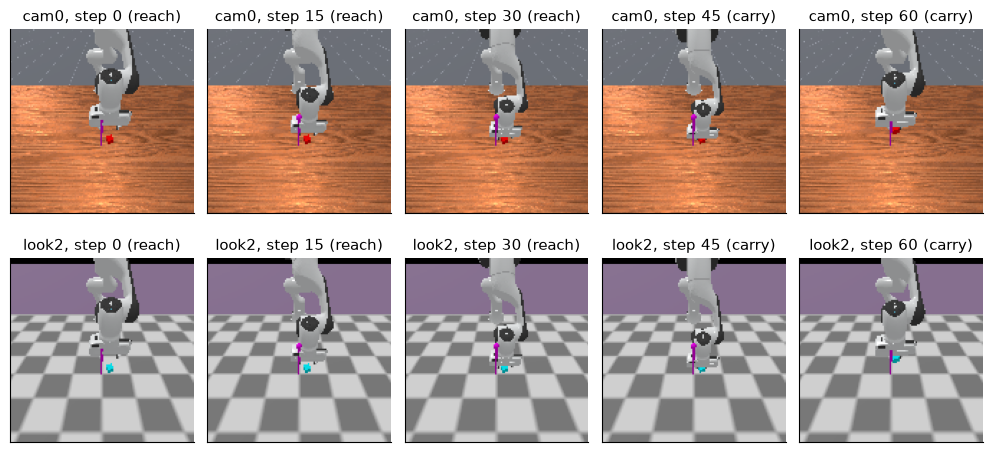

In [4]:
agents = {k: s1.load_agent(RUNS[k])[0] for k in ("cam0_s1", "look2_s2")}
D = {"cam0": load("cam0", range(100)), "look2": load("look2", range(100))}  # training demos 0-99, both renderings
assert np.abs(D["cam0"]["tcp"] - D["look2"]["tcp"]).max() < 1e-5  # same demo and step = same state

steps = [0, 15, 30, 45, 60]
fig, axs = plt.subplots(2, len(steps), figsize=(10, 4.9))
for r, dom in enumerate(("cam0", "look2")):
    for c, t in enumerate(steps):
        i = np.flatnonzero((D[dom]["demo"] == 0) & (D[dom]["t"] == t))[0]
        axs[r, c].imshow(D[dom]["rgb"][i].permute(1, 2, 0))
        axs[r, c].set(xticks=[], yticks=[], title=f"{dom}, step {t} ({PHASES[D[dom]['phase'][i]]})")
fig.tight_layout()
save(fig, "1_domains")

## 2. What the encoder's latent z looks like

Imitation training squeezes z onto a few directions that matter for the action ("regression collapse"): 256 numbers,
but almost all the variance lies in a handful of directions. The **effective rank** (participation ratio of z's PCA
spectrum, `s1.geometry`) counts them. Left and middle: the cam0 encoder's z on its 100 training demos, projected on its
top two principal directions and coloured by task phase and by the cube's x position. Right: the variance spectrum.

{'cam0': 3.1, 'look2': 6.4} effective rank (of 256 dimensions)


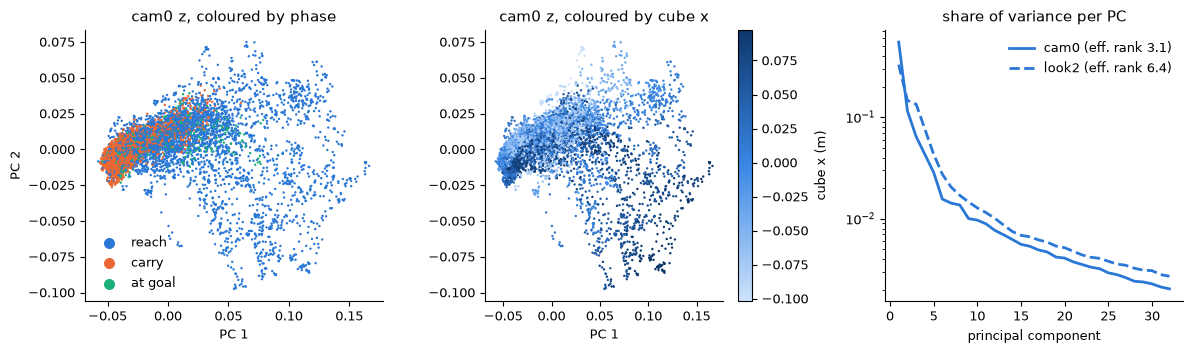

In [5]:
Z = {"cam0": z_of(agents["cam0_s1"], D["cam0"]["rgb"]), "look2": z_of(agents["look2_s2"], D["look2"]["rgb"])}
geo = {k: s1.geometry(Z[k], D[k]["phase"]) for k in Z}
print({k: round(g["eff_rank"], 1) for k, g in geo.items()}, "effective rank (of 256 dimensions)")

P2 = project(Z["cam0"], pca_basis(Z["cam0"]))
fig, axs = plt.subplots(1, 3, figsize=(12, 3.6))
phase_scatter(axs[0], P2, D["cam0"]["phase"])
axs[0].legend(markerscale=4, frameon=False)
axs[0].set(title="cam0 z, coloured by phase", xlabel="PC 1", ylabel="PC 2")
sc = axs[1].scatter(*P2.T, s=3, c=D["cam0"]["cube"][:, 0], cmap=BLUES, lw=0)
fig.colorbar(sc, ax=axs[1], label="cube x (m)")
axs[1].set(title="cam0 z, coloured by cube x", xlabel="PC 1")
for k, ls in (("cam0", "-"), ("look2", "--")):
    ev = np.linalg.svd(Z[k] - Z[k].mean(0), compute_uv=False) ** 2
    axs[2].plot(np.arange(1, 33), (ev / ev.sum())[:32], ls, c="#2a78d6", lw=2, label=f"{k} (eff. rank {geo[k]['eff_rank']:.1f})")
axs[2].set(yscale="log", title="share of variance per PC", xlabel="principal component")
axs[2].legend(frameon=False)
fig.tight_layout()
save(fig, "2_latent")

## 3. Same frames, different coordinates

Encode the **same states** with both agents (cam0 frames through the cam0 encoder, look 2 frames through the look 2
encoder). Each cloud has a similar shape, phases in a similar order, but in its own coordinates: nothing forces two
independently trained networks to use the same axes. Plugging the cam0 encoder straight into the look 2 controller
(the **identity map**) hands the controller vectors from the wrong place (right panel, drawn in the look 2 PCA basis).

closed loop (Step 1b, 250 episodes): identity 0.044, paired affine ceiling 0.756


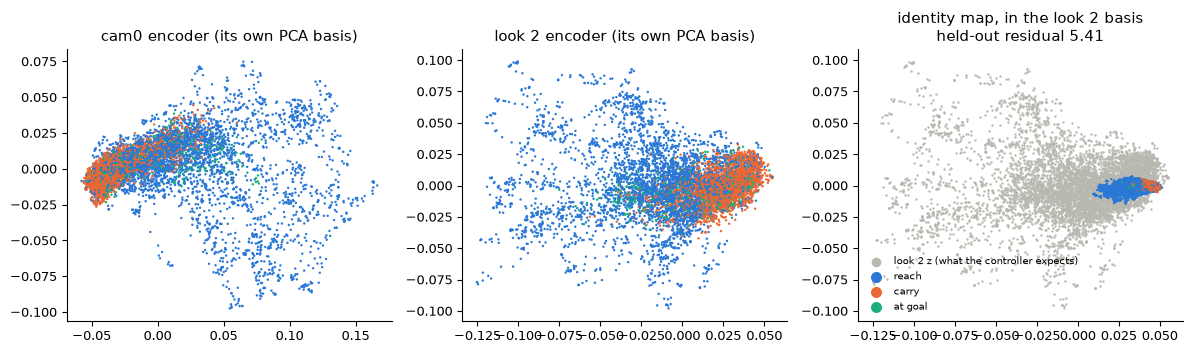

In [6]:
mx = json.load(open(MATRIX_1B))["success_once"]["look2"]["p1"]["fwd"]  # cam0 s1 encoder -> look 2 s2 controller, in cam0
# held-out paired frames (demos 400-497), for every residual below; only z is kept
H = {}
for dom, ag in (("cam0", "cam0_s1"), ("look2", "look2_s2")):
    h = load(dom, range(400, 498))
    H[dom] = dict(z=z_of(agents[ag], h["rgb"]), phase=h["phase"])
Bt = pca_basis(Z["look2"])
fig, axs = plt.subplots(1, 3, figsize=(12, 3.6))
phase_scatter(axs[0], project(Z["cam0"], pca_basis(Z["cam0"])), D["cam0"]["phase"])
axs[0].set(title="cam0 encoder (its own PCA basis)")
phase_scatter(axs[1], project(Z["look2"], Bt), D["look2"]["phase"])
axs[1].set(title="look 2 encoder (its own PCA basis)")
axs[2].scatter(*project(Z["look2"], Bt).T, s=3, c=GREY, lw=0, label="look 2 z (what the controller expects)")
phase_scatter(axs[2], project(Z["cam0"], Bt), D["cam0"]["phase"])
r_id = residual(fit_identity(Z["cam0"], Z["look2"]), H["cam0"]["z"], H["look2"]["z"])
axs[2].set(title=f"identity map, in the look 2 basis\nheld-out residual {r_id:.2f}")
axs[2].legend(markerscale=4, frameon=False, fontsize=7)
fig.tight_layout()
save(fig, "3_coordinates")
print(f"closed loop (Step 1b, 250 episodes): identity {mx['identity']:.3f}, paired affine ceiling {mx['affine']:.3f}")

## 4. Building correspondences without paired frames

In practice we never have the same state rendered in both domains. We do have each agent's own training demos, and in
both the robot moves. So each source frame (cam0 demos 0–49) is paired with the target frame (look 2 demos 50–99,
other episodes) whose next **8 steps of TCP motion** are nearest (z-scored per dimension). The pairs are not the same
state (the cube is elsewhere), only the same motion; that is enough because z is organised by action. Each row: source
frame, matched target frame, and their two motion chunks.

pair motion error: 2.77 mm (random pairs: 22.14 mm)


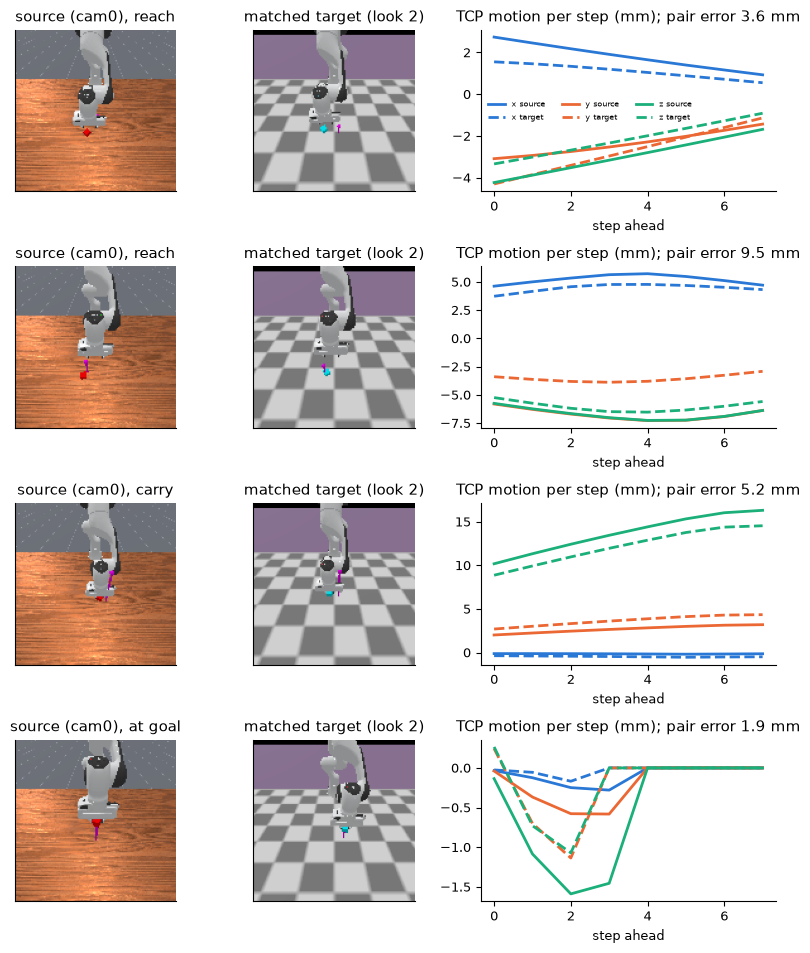

In [7]:
fit_s = D["cam0"]["demo"] < 50  # source: cam0 demos 0-49
fit_t = D["look2"]["demo"] >= 50  # target: look 2 demos 50-99
Ms, Mt = D["cam0"]["motion"][fit_s], D["look2"]["motion"][fit_t]
j = s5.nearest(*s5.zscore(Ms, Mt, "pooled"))  # (Ns,) index into the target fit frames
err = np.linalg.norm((Ms - Mt[j]).reshape(len(j), -1), axis=1) * 1e3
err_rand = np.linalg.norm((Ms - Mt[np.random.default_rng(0).integers(len(Mt), size=len(Ms))]).reshape(len(j), -1), axis=1) * 1e3
print(f"pair motion error: {err.mean():.2f} mm (random pairs: {err_rand.mean():.2f} mm)")

rgb_s, rgb_t = D["cam0"]["rgb"][fit_s], D["look2"]["rgb"][fit_t]
ph_s = D["cam0"]["phase"][fit_s]
rng = np.random.default_rng(1)
ex = [rng.choice(np.flatnonzero(ph_s == k)) for k in (0, 0, 1, 2)]  # examples across phases
fig, axs = plt.subplots(len(ex), 3, figsize=(8, 2.4 * len(ex)), gridspec_kw=dict(width_ratios=[1, 1, 1.6]))
for r, i in enumerate(ex):
    axs[r, 0].imshow(rgb_s[i].permute(1, 2, 0))
    axs[r, 1].imshow(rgb_t[j[i]].permute(1, 2, 0))
    axs[r, 0].set(xticks=[], yticks=[], title=f"source (cam0), {PHASES[ph_s[i]]}")
    axs[r, 1].set(xticks=[], yticks=[], title="matched target (look 2)")
    for a, (lab, c) in enumerate(zip("xyz", PHASE_C)):
        axs[r, 2].plot(Ms[i, :, a] * 1e3, c=c, lw=2, label=f"{lab} source")
        axs[r, 2].plot(Mt[j[i], :, a] * 1e3, "--", c=c, lw=2, label=f"{lab} target")
    axs[r, 2].set(title=f"TCP motion per step (mm); pair error {err[i]:.1f} mm", xlabel="step ahead")
axs[0, 2].legend(ncol=3, fontsize=6, frameon=False)
fig.tight_layout()
save(fig, "4_motion_pairs")

## 5. Fitting the map: orthogonal vs affine vs paired ceiling

From the motion pairs we fit a linear map T(z) = R z + b in closed form, either **orthogonal** (a rotation plus shift,
`nn_orth`) or **affine** (least squares, `nn_affine`). The **paired ceiling** is the affine map fitted on true paired
frames (same state, both cameras), which we could not have in practice. Each panel: held-out look 2 z (grey, what the
controller expects) and mapped cam0 z of the same states (coloured), in the look 2 PCA basis; segments join 40 mapped
points to their true targets. Within a robot, affine is the default.

identity                 held-out residual 5.41   closed loop 0.044 = 6% of the ceiling (250 episodes)
nn_orth                  held-out residual 0.80   closed loop 0.460 = 61% of the ceiling (250 episodes)
nn_affine                held-out residual 0.59   closed loop 0.564 = 75% of the ceiling (250 episodes)
paired ceiling (affine)  held-out residual 0.37   closed loop 0.756 = 100% of the ceiling (250 episodes)


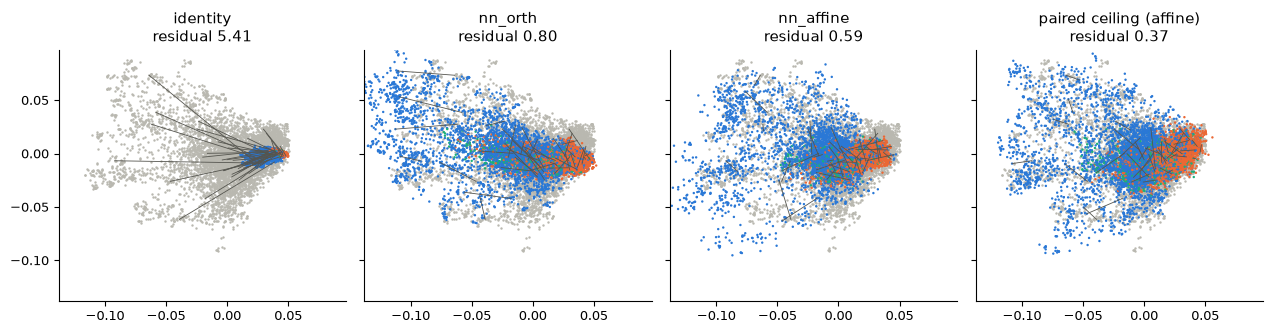

In [8]:
Zs, Zt = Z["cam0"][fit_s], Z["look2"][fit_t]
maps = {"identity": fit_identity(Zs, Zt), "nn_orth": fit_procrustes_paired(Zs, Zt[j]),
        "nn_affine": fit_affine_paired(Zs, Zt[j]), "paired ceiling (affine)": fit_affine_paired(Z["cam0"], Z["look2"])}


def map_panels(maps, Hs, Ht, phase, basis, name, lim):
    fig, axs = plt.subplots(1, len(maps), figsize=(3.2 * len(maps), 3.4), sharex=True, sharey=True)
    pt, sub = project(Ht, basis), np.random.default_rng(0).choice(len(Ht), 40, replace=False)
    res = {}
    for ax, (m, T) in zip(axs, maps.items()):
        pm = project(apply(T, Hs), basis)
        res[m] = residual(T, Hs, Ht)
        ax.scatter(*pt.T, s=3, c=GREY, lw=0)
        phase_scatter(ax, pm, phase)
        ax.plot(np.stack([pm[sub, 0], pt[sub, 0]]), np.stack([pm[sub, 1], pt[sub, 1]]), c="#55554f", lw=0.6)
        ax.set(title=f"{m}\nresidual {res[m]:.2f}", xlim=lim, ylim=lim)
    fig.tight_layout()
    save(fig, name)
    return res


lim = np.percentile(project(H["look2"]["z"], Bt), [0.5, 99.5]) * 1.4
res5 = map_panels(maps, H["cam0"]["z"], H["look2"]["z"], H["cam0"]["phase"], Bt, "5_maps", lim)
cl = {"identity": mx["identity"], "nn_orth": json.load(open(ORTH_P1))["stitch"]["fwd"]["nn_orth_motion"]["success_once"],
      "nn_affine": json.load(open(MOTION_P1))["stitch"]["fwd"]["nn_affine_motion"]["success_once"], "paired ceiling (affine)": mx["affine"]}
for m in maps:
    print(f"{m:24s} held-out residual {res5[m]:.2f}   closed loop {cl[m]:.3f} = {cl[m] / mx['affine']:.0%} of the ceiling (250 episodes)")

## 6. Across robots

Now a Panda encoder (look 2, seed 1) feeds an **xArm** controller (cam0, seed 2), played on the xArm in look 2. The
source pairs come from the encoder's own Panda demos and the target pairs from the xArm controller's own demos: two
different robots, matched by what their grippers did. The paired ceiling uses xArm demos rendered in both domains.
Across robots the **orthogonal** map is the one that works in closed loop. Note that its held-out residual is *not*
lower than the affine map's; the last panel compares how far each map spreads z (std of the mapped z along each target
principal direction, relative to the target's). An affine fit on noisier cross-robot pairs can shrink z toward the
target mean, which lowers the residual but gives the controller less to read. That reading is a hypothesis; the cause
has not been diagnosed.

number of parameters: 6.12M
number of parameters: 6.17M


pair motion error: 3.03 mm


identity                 held-out residual 6.09
nn_orth                  held-out residual 1.25   closed loop 0.384 (1000 episodes)
nn_affine                held-out residual 0.97   closed loop 0.279 (1000 episodes)
paired ceiling (affine)  held-out residual 0.43   closed loop 0.573 (1000 episodes)


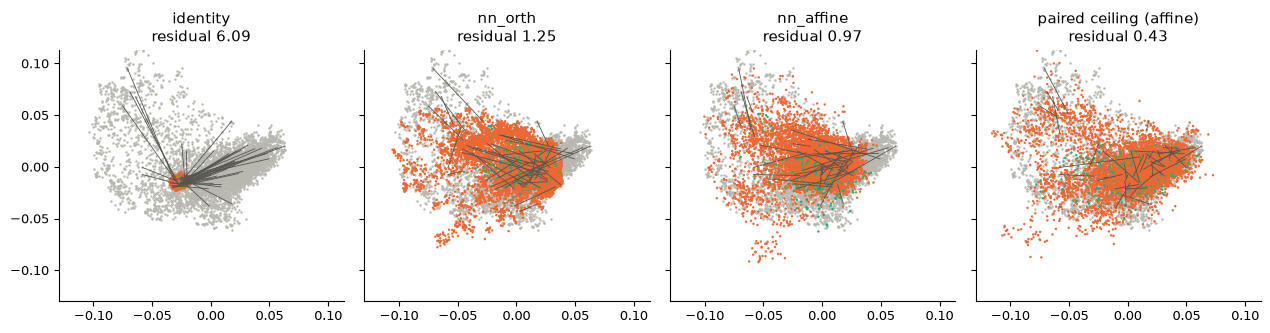

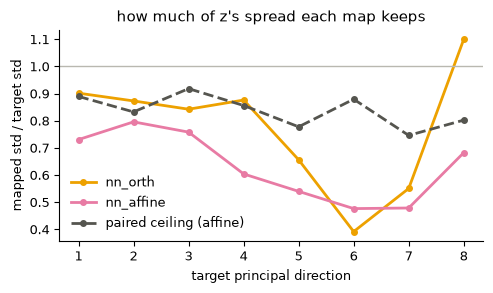

In [9]:
ag = {k: s1.load_agent(RUNS[k])[0] for k in ("look2_s1", "xarm_cam0_s2")}
src = load("look2_r", range(50))  # the encoder's own Panda demos 0-49
tgt = load("xarm_cam0", range(50, 100))  # the controller's own xArm demos 50-99
pu, pv = load("xarm_look2", range(100)), load("xarm_cam0", range(100))  # paired xArm frames, both renderings
hu, hv = load("xarm_look2", range(400, 496)), load("xarm_cam0", range(400, 496))
Zs6, Zt6 = z_of(ag["look2_s1"], src["rgb"]), z_of(ag["xarm_cam0_s2"], tgt["rgb"])
Pu, Pv = z_of(ag["look2_s1"], pu["rgb"]), z_of(ag["xarm_cam0_s2"], pv["rgb"])
Hu, Hv = z_of(ag["look2_s1"], hu["rgb"]), z_of(ag["xarm_cam0_s2"], hv["rgb"])
del src["rgb"], pu["rgb"], pv["rgb"], hu["rgb"], hv["rgb"]
j6 = s5.nearest(*s5.zscore(src["motion"], tgt["motion"], "pooled"))
print(f"pair motion error: {np.linalg.norm((src['motion'] - tgt['motion'][j6]).reshape(len(j6), -1), axis=1).mean() * 1e3:.2f} mm")
maps6 = {"identity": fit_identity(Zs6, Zt6), "nn_orth": fit_procrustes_paired(Zs6, Zt6[j6]),
         "nn_affine": fit_affine_paired(Zs6, Zt6[j6]), "paired ceiling (affine)": fit_affine_paired(Pu, Pv)}
B6 = pca_basis(Pv, k=8)
res6 = map_panels(maps6, Hu, Hv, hu["phase"], (B6[0], B6[1][:2]), "6_maps_xarm",
                  np.percentile(project(Hv, (B6[0], B6[1][:2])), [0.5, 99.5]) * 1.4)

ce, own = json.load(open(EMB_CEIL))["aligners"], json.load(open(EMB_OWN))["aligners"]
cl6 = {"nn_orth": own["nn_orth_motion_own"]["success_once"], "nn_affine": own["nn_affine_motion_own"]["success_once"],
       "paired ceiling (affine)": ce["affine"]["success_once"]}
for m in maps6:
    print(f"{m:24s} held-out residual {res6[m]:.2f}" + (f"   closed loop {cl6[m]:.3f} (1000 episodes)" if m in cl6 else ""))

fig, ax = plt.subplots(figsize=(5, 3))
sd_t = project(Hv, B6).std(0)
for m, c, ls in (("nn_orth", "#eda100", "-"), ("nn_affine", "#e87ba4", "-"), ("paired ceiling (affine)", "#55554f", "--")):  # not the phase colours
    T = maps6[m]
    ax.plot(np.arange(1, 9), project(apply(T, Hu), B6).std(0) / sd_t, ls, c=c, lw=2, marker="o", ms=4, label=m)
ax.axhline(1, c=GREY, lw=1)
ax.set(xlabel="target principal direction", ylabel="mapped std / target std", title="how much of z's spread each map keeps")
ax.legend(frameon=False)
fig.tight_layout()
save(fig, "6_spread_xarm")

## 7. Saliency: what does each encoder look at?

For a few states, the gradient of ‖z − z̄‖ (z̄ = the encoder's mean z over its demos) with respect to the input pixels,
summed over colour channels, shows which pixels move z. The same three states are shown through the cam0 encoder on
cam0 frames and the look 2 encoder on look 2 frames. Markers: × the cube's centre, + the TCP (projected with the
stored camera matrices).

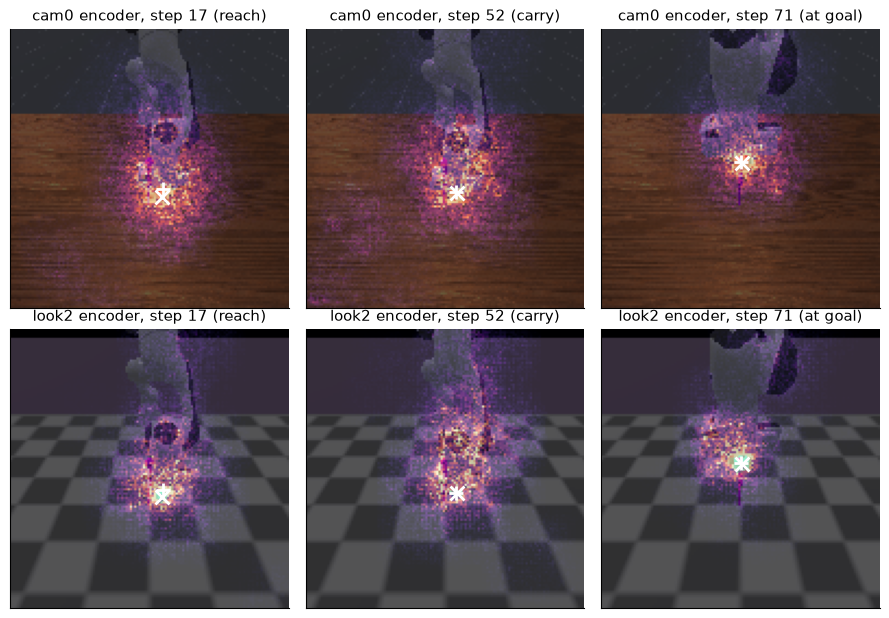

In [10]:
def saliency(agent, rgb, zbar):
    # rgb (B, 3, 128, 128) uint8 -> (B, 128, 128) |d ||z - zbar|| / d pixel|, summed over channels
    x = (rgb.float() / 255.0).to(DEV).requires_grad_(True)
    (agent.visual_encoder(x) - torch.tensor(zbar, device=DEV)).norm(dim=1).sum().backward()
    return x.grad.abs().sum(1).cpu().numpy()


demo = next(d for d in range(100) if len(np.unique(D["cam0"]["phase"][D["cam0"]["demo"] == d])) == 3)  # first demo with all phases
idx = [np.flatnonzero((D["cam0"]["demo"] == demo) & (D["cam0"]["phase"] == k)) for k in range(3)]
idx = [i[len(i) // 2] for i in idx]  # the middle frame of each phase
fig, axs = plt.subplots(2, len(idx), figsize=(9, 6.2))
for r, (dom, a) in enumerate((("cam0", "cam0_s1"), ("look2", "look2_s2"))):
    sal = saliency(agents[a], D[dom]["rgb"][idx], Z[dom].mean(0))
    for c, i in enumerate(idx):
        ax = axs[r, c]
        ax.imshow(D[dom]["rgb"][i].permute(1, 2, 0))
        ax.imshow(sal[c] / np.percentile(sal[c], 99.5), cmap="magma", alpha=0.6, vmin=0, vmax=1)
        for p, mk in ((D[dom]["cube"][i], "x"), (D[dom]["tcp"][i], "+")):
            ax.plot(*pixel(p, D[dom]["K"][i], D[dom]["E"][i]), mk, c="white", ms=10, mew=2)
        ax.set(xticks=[], yticks=[], title=f"{dom} encoder, step {D[dom]['t'][i]} ({PHASES[D[dom]['phase'][i]]})")
fig.tight_layout()
save(fig, "7_saliency")

## 8. Closed loop

Three clips from `scripts/notebook_rollouts.py`: the cam0 s1 encoder driving the look 2 s2 controller in cam0, through
the identity map and through `nn_affine` on motion pairs (one success, one failure). **10 episodes per map is
illustrative, not a measurement** (the 250-episode numbers are in section 5). Initial states are random and differ
between the clips.

In [11]:
ROLL = OUT / "rollouts"
r = json.load(open(ROLL / "metrics.json"))["maps"]
print({m: f"{sum(v['success_once'])}/10 success_once" for m, v in r.items()})
ok, fail = r["nn_affine"]["success_once"].index(True), r["nn_affine"]["success_once"].index(False)
clips = [("identity", 0, "identity map"), ("nn_affine", ok, "nn_affine: success"), ("nn_affine", fail, "nn_affine: failure")]
html = "".join(f"<figure style='display:inline-block;margin:4px'><figcaption>{cap} (episode {k})</figcaption>"
               + Video(str(ROLL / m / f"{k}.mp4"), embed=True, width=300, html_attributes="controls loop muted autoplay")._repr_html_()
               + "</figure>" for m, k, cap in clips)
display(HTML(html))

{'identity': '0/10 success_once', 'nn_affine': '7/10 success_once'}


## 9. Mario in one picture

The same idea started in Super Mario Bros (discrete actions, level 1-1). t-SNE of each encoder's latent on its training
frames, coloured by action. With plain behaviour cloning (BC) the actions are mixed; with **SCIL** (a SupCon loss on the
action labels) each action collapses into its own cluster ("action collapse"), so a map fitted only on action labels
lines two encoders up. TACO alone does not cluster by action; SCIL + TACO keeps the clusters.

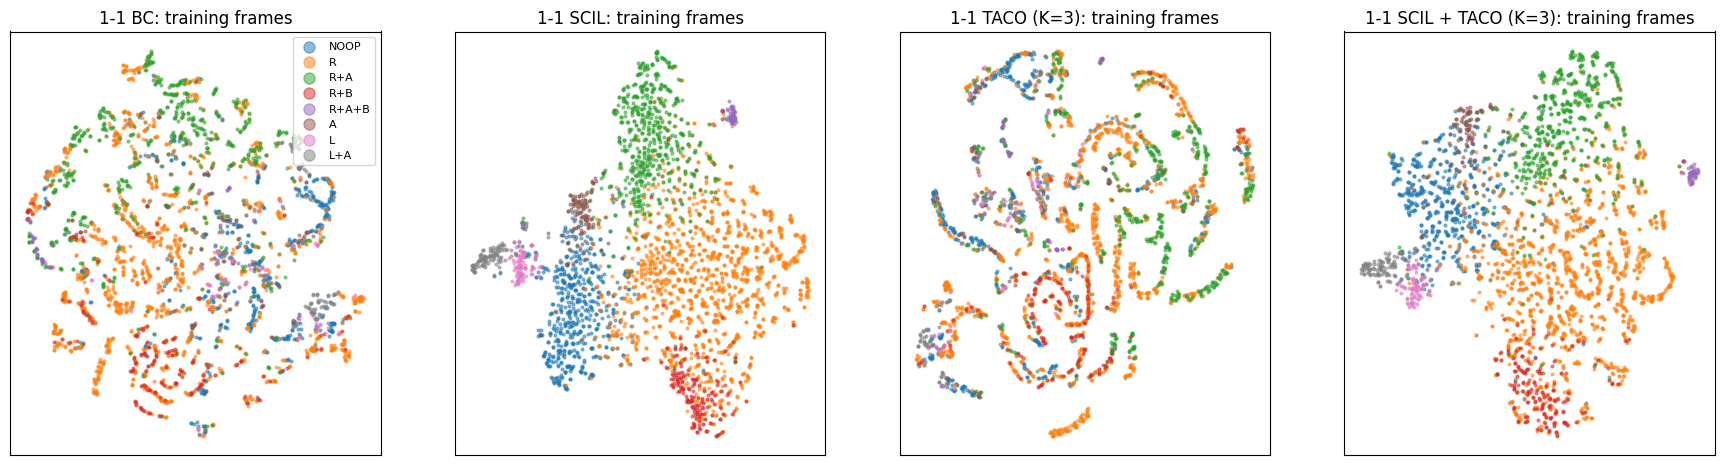

In [12]:
display(Image(TSNE, width=900))

**Recap.** Imitation-trained encoders are low-dimensional and organised by what the robot does; two such encoders
differ by roughly a linear change of coordinates; pairs matched by motion, from each agent's own demos, are enough to
fit that change in closed form: affine within a robot, orthogonal across robots.